# Foto → humor e energia — Parte 1: treinar o modelo

**O que este notebook faz:** ensina um modelo a olhar uma foto e dar duas notas:
**valência** (humor: desagradável → agradável) e **energia** (arousal: calma → agitada).

**Como:**
1. O **CLIP** (ViT-B/32), já pré-treinado, transforma cada foto num vetor de 512 números (*embedding*). Ele fica **congelado** — não mexemos nos pesos dele.
2. Uma **regressão Ridge de 2 saídas** aprende a ir do vetor para as notas, usando as **900 fotos do OASIS**, que foram avaliadas por ~100 pessoas cada (escala 1–7).
3. Avaliamos com **validação cruzada agrupada** e, no fim, treinamos com tudo e salvamos o modelo no Drive.

No teste de viabilidade (14/11/2026) esse método deu **r = 0,85 (humor)** e **r = 0,82 (energia)**. Este notebook deve reproduzir algo bem próximo.

> Ambiente: Colab com GPU é mais rápido (Ambiente de execução → Alterar tipo → T4), mas na CPU também roda em poucos minutos.

## 1. Configuração
Ajuste `PASTA` para a pasta do projeto no seu Drive.

In [1]:
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA = Path("/content/drive/MyDrive/mapa-sonoro")   # <- ajuste se a sua pasta tiver outro nome
    NO_COLAB = True
except ImportError:                                        # rodando fora do Colab
    PASTA = Path("mapa-sonoro-local")
    NO_COLAB = False

PASTA_OASIS = PASTA / "oasis"
PASTA_MODELOS = PASTA / "modelos"
PASTA_OASIS.mkdir(parents=True, exist_ok=True)
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)

SEMENTE = 0
NOME_CLIP = "openai/clip-vit-base-patch32"
print("Pasta do projeto:", PASTA)

Mounted at /content/drive
Pasta do projeto: /content/drive/MyDrive/mapa-sonoro


## 2. Baixar o OASIS
Só baixa na primeira vez (~90 MB); depois fica guardado no Drive.
O OASIS é de uso livre em pesquisa (Kurdi, Lozano & Banaji, 2017).

In [2]:
import subprocess, zipfile

csv_oasis = PASTA_OASIS / "OASIS.csv"
if not csv_oasis.exists():
    zip_path = PASTA_OASIS / "oasis.zip"
    subprocess.run(["curl", "-sSL", "-o", str(zip_path), "https://benedekkurdi.com/oasis.php"], check=True)
    with zipfile.ZipFile(zip_path) as z:
        for membro in z.namelist():
            if membro.startswith("__MACOSX") or membro.endswith(".DS_Store"):
                continue                    # lixo do macOS dentro do zip
            z.extract(membro, PASTA_OASIS)
    zip_path.unlink()

print("Imagens:", len(list((PASTA_OASIS / "Images").glob("*.jpg"))))

Imagens: 900


## 3. Ler as notas
Cada linha é uma foto. Usamos a **média** das notas (`Valence_mean`, `Arousal_mean`).

**Grupo:** o OASIS tem séries de fotos quase iguais ("Acorns 1", "Acorns 2", "Acorns 3").
Se uma ficar no treino e a irmã no teste, o modelo "cola" e o resultado fica otimista demais.
Por isso criamos um **grupo por tema**, e fotos do mesmo grupo ficam sempre do mesmo lado.

In [3]:
import numpy as np
import pandas as pd

df = pd.read_csv(csv_oasis)
df["arquivo"] = df["Theme"].str.strip() + ".jpg"
df["grupo"] = df["Theme"].str.replace(r"\s*\d+$", "", regex=True).str.strip()

Y = df[["Valence_mean", "Arousal_mean"]].to_numpy()
EIXOS = ["valência", "energia"]

print(f"{len(df)} fotos, {df.grupo.nunique()} temas")
print(df.Category.value_counts().to_string())
print(f"\nCorrelação entre valência e energia nas notas humanas: {np.corrcoef(Y.T)[0, 1]:.2f}"
      "  (perto de 0 = eixos independentes, bom para usar os dois)")
df[["Theme", "Category", "Valence_mean", "Arousal_mean"]].describe().round(2)

900 fotos, 249 temas
Category
Person    346
Scene     220
Object    200
Animal    134

Correlação entre valência e energia nas notas humanas: -0.06  (perto de 0 = eixos independentes, bom para usar os dois)


,Valence_mean,Arousal_mean
count,900.00,900.00
mean,4.33,3.67
std,1.23,0.84
min,1.11,1.69
25%,3.49,3.18
50%,4.52,3.73
75%,5.33,4.27
max,6.49,5.72


### Teto de ruído
Notas humanas têm ruído. Com ~100 pessoas por foto, a média é bem confiável.
O **teto** é a correlação máxima que um modelo perfeito conseguiria, dado esse ruído.

In [4]:
for eixo, col in [("valência", "Valence"), ("energia", "Arousal")]:
    erro_da_media = (df[f"{col}_SD"] ** 2 / df[f"{col}_N"]).mean()
    confiabilidade = 1 - erro_da_media / df[f"{col}_mean"].var()
    print(f"{eixo:9s}  confiabilidade = {confiabilidade:.3f}   teto de r ≈ {np.sqrt(confiabilidade):.3f}")

valência   confiabilidade = 0.992   teto de r ≈ 0.996
energia    confiabilidade = 0.960   teto de r ≈ 0.980


## 4. Extrair os embeddings com o CLIP
Cada foto vira um vetor de 512 números. Normalizamos o vetor (comprimento 1), como o CLIP faz internamente.
O resultado é salvo no Drive para não precisar repetir.

In [6]:
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

disp = "cuda" if torch.cuda.is_available() else "cpu"
clip = CLIPModel.from_pretrained(NOME_CLIP).eval().to(disp)
proc = CLIPProcessor.from_pretrained(NOME_CLIP)

@torch.no_grad()
def embeddings(imagens, lote=32):
    # Recebe uma lista de imagens PIL e devolve uma matriz (n, 512) normalizada
    saidas = []
    for i in range(0, len(imagens), lote):
        x = proc(images=imagens[i:i + lote], return_tensors="pt").to(disp)
        saida_visual = clip.vision_model(pixel_values=x["pixel_values"])
        e = clip.visual_projection(saida_visual.pooler_output)
        saidas.append(torch.nn.functional.normalize(e, dim=-1).cpu())
    return torch.cat(saidas).numpy()

cache = PASTA_MODELOS / "clip_oasis_embeddings.npy"
if cache.exists():
    X = np.load(cache)
else:
    imgs = [Image.open(PASTA_OASIS / "Images" / a).convert("RGB") for a in df.arquivo]
    X = embeddings(imgs)
    np.save(cache, X)
print("X:", X.shape, "| dispositivo:", disp)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

X: (900, 512) | dispositivo: cpu


## 5. Validação cruzada agrupada (5 folds)
Para cada fold: treina com 80% dos temas e testa nos 20% restantes, que o modelo nunca viu.

O modelo é um `Pipeline`:
- `StandardScaler`: coloca as 512 colunas na mesma escala;
- `RidgeCV`: regressão linear com penalidade (evita decorar com só 900 exemplos). Ele mesmo escolhe a força da penalidade (`alpha`).

Comparamos com a **linha de base**: sempre chutar a média do treino.

In [7]:
from scipy.stats import pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def novo_modelo():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 20)))

folds = list(GroupKFold(n_splits=5).split(X, Y, groups=df.grupo))
P = np.zeros_like(Y)       # previsões fora da amostra
P0 = np.zeros_like(Y)      # linha de base
alphas = []
for treino, teste in folds:
    m = novo_modelo().fit(X[treino], Y[treino])
    P[teste] = m.predict(X[teste])
    P0[teste] = Y[treino].mean(axis=0)
    alphas.append(m[-1].alpha_)

linhas = []
for j, eixo in enumerate(EIXOS):
    linhas.append({"eixo": eixo,
                   "r": pearsonr(Y[:, j], P[:, j])[0],
                   "erro médio (MAE)": mean_absolute_error(Y[:, j], P[:, j]),
                   "MAE chutando a média": mean_absolute_error(Y[:, j], P0[:, j])})
print("alphas escolhidos por fold:", np.round(alphas, 1))
pd.DataFrame(linhas).round(3)

alphas escolhidos por fold: [483.3 263.7 483.3 483.3 263.7]


,eixo,r,erro médio (MAE),MAE chutando a média
0,valência,0.828,0.538,1.028
1,energia,0.823,0.372,0.677


### Por tipo de foto
`Scene` (paisagens/cenários) e `Person` (retratos) são os casos de uso do projeto.

In [8]:
por_cat = []
for cat, g in df.groupby("Category"):
    i = g.index
    por_cat.append({"categoria": cat, "n": len(i),
                    "r valência": pearsonr(Y[i, 0], P[i, 0])[0],
                    "r energia": pearsonr(Y[i, 1], P[i, 1])[0]})
pd.DataFrame(por_cat).round(2)

,categoria,n,r valência,r energia
0,Animal,134,0.70,0.61
1,Object,200,0.84,0.85
2,Person,346,0.83,0.72
3,Scene,220,0.88,0.74


### Previsto × real
Cada ponto é uma foto prevista por um modelo que **não** a viu no treino. Quanto mais perto da diagonal, melhor.

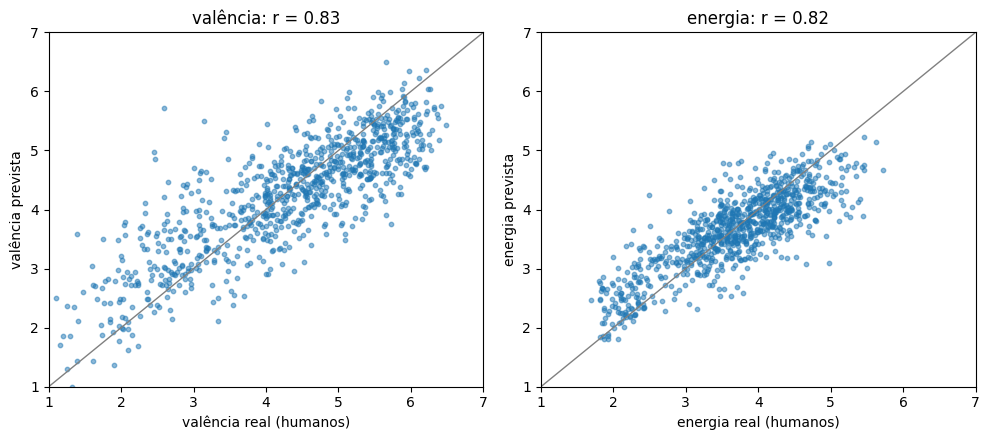

In [9]:
import matplotlib.pyplot as plt

fig, eixos_plot = plt.subplots(1, 2, figsize=(10, 4.5))
for j, (ax, eixo) in enumerate(zip(eixos_plot, EIXOS)):
    ax.scatter(Y[:, j], P[:, j], s=10, alpha=0.5)
    ax.plot([1, 7], [1, 7], color="gray", lw=1)
    ax.set(xlabel=f"{eixo} real (humanos)", ylabel=f"{eixo} prevista",
           title=f"{eixo}: r = {pearsonr(Y[:, j], P[:, j])[0]:.2f}", xlim=(1, 7), ylim=(1, 7))
plt.tight_layout(); plt.show()

### Onde o modelo mais erra
Útil para entender limites: em geral são fotos cujo sentido depende de contexto (ironia, detalhe pequeno).

In [10]:
erros = df[["Theme", "Category"]].assign(
    val_real=Y[:, 0], val_prev=P[:, 0], ene_real=Y[:, 1], ene_prev=P[:, 1],
    erro_total=np.abs(Y - P).sum(axis=1))
erros.sort_values("erro_total", ascending=False).head(10).round(2)

,Theme,Category,val_real,val_prev,ene_real,ene_prev,erro_total
326,Fire 10,Scene,2.47,4.85,4.66,3.07,3.97
761,Sleepy pose 1,Person,2.59,5.73,3.48,3.80,3.46
167,Cockroach 3,Animal,2.45,4.97,3.94,3.39,3.07
233,Dirt 1,Scene,1.61,2.73,4.98,3.09,3.01
868,War 6,Person,1.39,3.59,5.02,4.45,2.76
231,Destruction 9,Scene,3.56,2.56,2.49,4.24,2.76
675,Rollercoaster 2,Scene,5.37,3.95,5.12,3.80,2.74
318,Fire 2,Scene,1.96,3.49,4.68,3.62,2.59
517,Neonazi 1,Person,2.04,3.74,4.44,3.61,2.53
693,Sad face 7,Person,3.14,5.50,3.80,3.66,2.50


## 6. Treinar o modelo final com as 900 fotos e salvar
A validação mostrou quanto o método acerta. Agora treinamos com **tudo** (mais dados = modelo um pouco melhor) e salvamos no Drive.

Junto com o modelo, salvamos a **média e o desvio padrão** das notas do OASIS.
Na Parte 2 eles servem para padronizar as notas das fotos (z-score) e compará-las com as das músicas, que usam outra escala (1–9).

In [11]:
import joblib, sklearn, transformers
from datetime import date

final = novo_modelo().fit(X, Y)

pacote = {
    "modelo": final,
    "clip": NOME_CLIP,
    "eixos": ["valencia", "energia"],
    "escala": "OASIS 1-7",
    "media_oasis": Y.mean(axis=0),
    "desvio_oasis": Y.std(axis=0),
    "validacao": {"r_valencia": float(pearsonr(Y[:, 0], P[:, 0])[0]),
                  "r_energia": float(pearsonr(Y[:, 1], P[:, 1])[0])},
    "versoes": {"sklearn": sklearn.__version__, "transformers": transformers.__version__},
    "data": str(date.today()),
}
arquivo_modelo = PASTA_MODELOS / "foto_humor_energia.joblib"
joblib.dump(pacote, arquivo_modelo)
print("Salvo em", arquivo_modelo, "| alpha final:", round(final[-1].alpha_, 1))

Salvo em /content/drive/MyDrive/mapa-sonoro/modelos/foto_humor_energia.joblib | alpha final: 483.3


## 7. Testar com uma foto sua
No Colab, rode a célula e escolha uma ou mais fotos. Lembrete honesto: o OASIS tem muitas fotos de conteúdo forte;
fotos do dia a dia tendem a cair numa faixa mais estreita de notas.

In [12]:
def notas_da_foto(imagens):
    # Devolve uma tabela com valência e energia (escala 1-7) para uma lista de imagens PIL
    pac = joblib.load(arquivo_modelo)
    p = pac["modelo"].predict(embeddings(imagens))
    return pd.DataFrame(p, columns=["valência (1-7)", "energia (1-7)"]).round(2)

if NO_COLAB:
    from google.colab import files
    import io
    enviadas = files.upload()
    nomes = list(enviadas)
    fotos = [Image.open(io.BytesIO(enviadas[n])).convert("RGB") for n in nomes]
else:                                   # fora do Colab: testa com 3 fotos do próprio OASIS
    nomes = df.arquivo[:3].tolist()
    fotos = [Image.open(PASTA_OASIS / "Images" / n).convert("RGB") for n in nomes]

resultado = notas_da_foto(fotos)
resultado.insert(0, "foto", nomes)
resultado

Saving Pink outfit Sarah Teyssier.jpg to Pink outfit Sarah Teyssier.jpg


,foto,valência (1-7),energia (1-7)
0,Pink outfit Sarah Teyssier.jpg,5.17,3.33
